In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
df2 = pd.read_csv('../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', encoding='latin1') 
df2.columns = df2.columns.str.strip() 
print(df2.shape) 
print(df2[['Timestamp', 'Label']].head())

(225745, 85)
       Timestamp   Label
0  7/7/2017 3:30  BENIGN
1  7/7/2017 3:30  BENIGN
2  7/7/2017 3:30  BENIGN
3  7/7/2017 3:30  BENIGN
4  7/7/2017 3:30  BENIGN


2017-07-07 15:30:00 2017-07-07 17:02:00


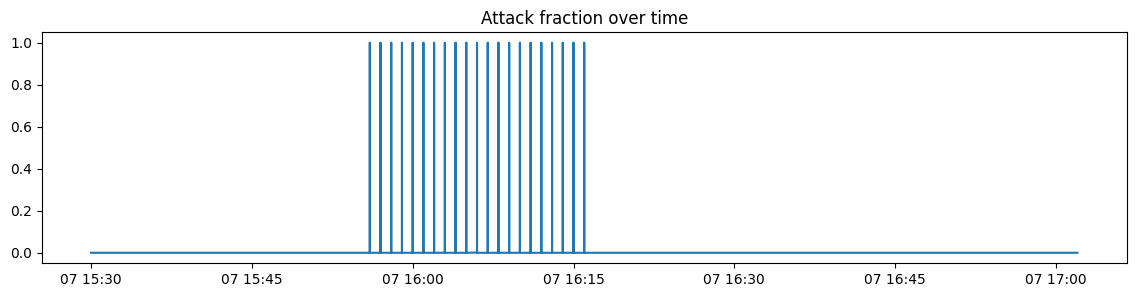

In [3]:
t = pd.to_datetime(df2['Timestamp'], format='%m/%d/%Y %H:%M') 
t = t.where(t.dt.hour >= 8, t + pd.Timedelta(hours=12)) 
df2['t'] = t 
df2 = df2.sort_values('t', kind='stable').reset_index(drop=True) 
print(df2['t'].min(), df2['t'].max()) 
is_attack = (df2['Label'] != 'BENIGN').astype(int) 
plt.figure(figsize=(14, 3)) 
plt.plot(df2['t'], is_attack.rolling(1000).mean()) 
plt.title('Attack fraction over time') 
plt.show()

93 minutes, 21 attack minutes
count    21.000000
mean      0.704216
std       0.073087
min       0.479886
25%       0.687919
50%       0.706047
75%       0.740590
max       0.822665
Name: Label, dtype: float64


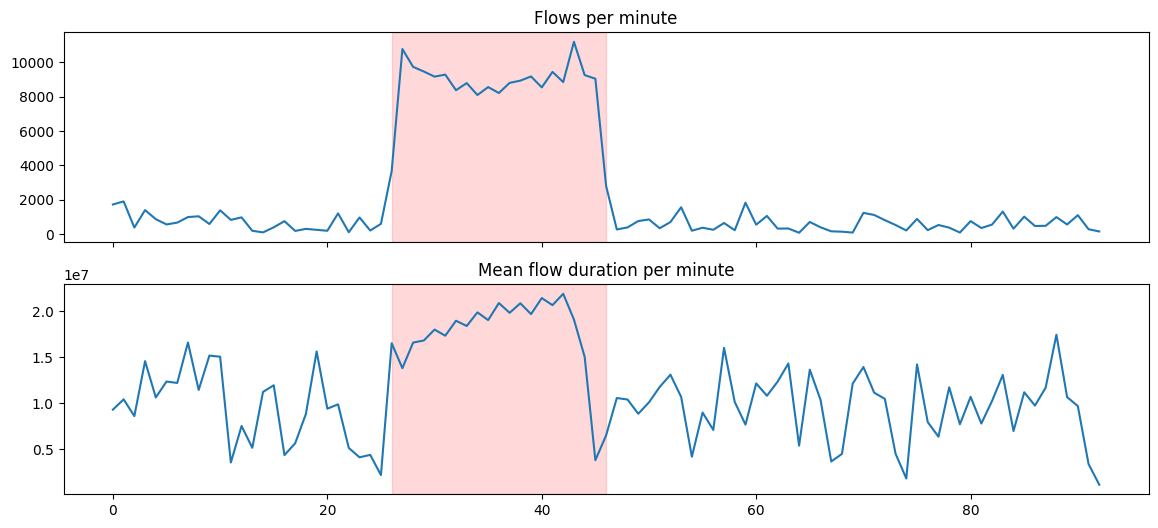

In [4]:
df2['minute'] = df2['t'].dt.floor('min')
full = pd.date_range(df2['minute'].min(), df2['minute'].max(), freq='min')
flows_per_min = df2.groupby('minute').size().reindex(full, fill_value=0)
dur_per_min = df2.groupby('minute')['Flow Duration'].mean().reindex(full, fill_value=0)
attack_frac = (df2['Label'] != 'BENIGN').groupby(df2['minute']).mean().reindex(full, fill_value=0)
y = (attack_frac > 0).values
print(len(full), 'minutes,', y.sum(), 'attack minutes')
print(attack_frac[attack_frac > 0].describe())

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(flows_per_min.values); ax[0].set_title('Flows per minute')
ax[1].plot(dur_per_min.values); ax[1].set_title('Mean flow duration per minute')
for a in ax:
    a.fill_between(range(len(y)), 0, 1, where=y, transform=a.get_xaxis_transform(), color='red', alpha=0.15)
plt.show()

In [5]:
from sklearn.metrics import roc_auc_score 
for name, s in [('flows/min', flows_per_min.values), ('duration/min', dur_per_min.values)]: 
    for w in [1, 3, 5]: 
        sm = np.convolve(s, np.ones(w) / w, mode='same') 
        print(name, 'window', w, 'AUC', round(roc_auc_score(y, sm), 3))

flows/min window 1 AUC 1.0
flows/min window 3 AUC 1.0
flows/min window 5 AUC 1.0
duration/min window 1 AUC 0.905
duration/min window 3 AUC 0.907
duration/min window 5 AUC 0.946


In [6]:
x = flows_per_min.values.astype(float)
start = int(np.argmax(y))          # first attack minute
print('attack starts at minute', start)

def causal_ma(x, N):
    return np.convolve(x, np.ones(N) / N)[:len(x)]

rows = []
for N in [1, 3, 5]:
    s = causal_ma(x, N)
    base = s[N-1:start]                      # baseline from normal minutes only
    thr = base.mean() + 3 * base.std()
    pred = s > thr
    TP = (pred & y).sum(); FP = (pred & ~y).sum(); FN = (~pred & y).sum()
    p = TP / (TP + FP) if TP + FP else 0
    r = TP / (TP + FN)
    f = 2 * p * r / (p + r) if p + r else 0
    first = int(np.argmax(pred[start:])) if pred[start:].any() else None
    rows.append(dict(window=N, threshold=round(thr), precision=round(p, 3), recall=round(r, 3),
                     f1=round(f, 3), FP=int(FP), FN=int(FN), delay_min=first))
pd.DataFrame(rows)

attack starts at minute 26


,window,threshold,precision,recall,f1,FP,FN,delay_min
0,1,2215,1.000,1.000,1.000,0,0,0
1,3,1601,0.952,0.952,0.952,1,1,1
2,5,1451,0.870,0.952,0.909,3,1,1


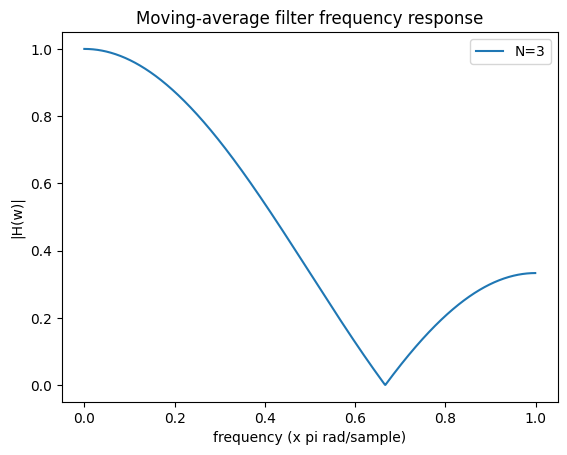

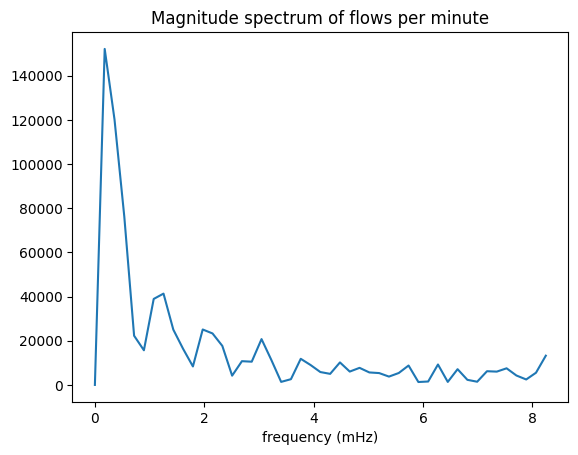

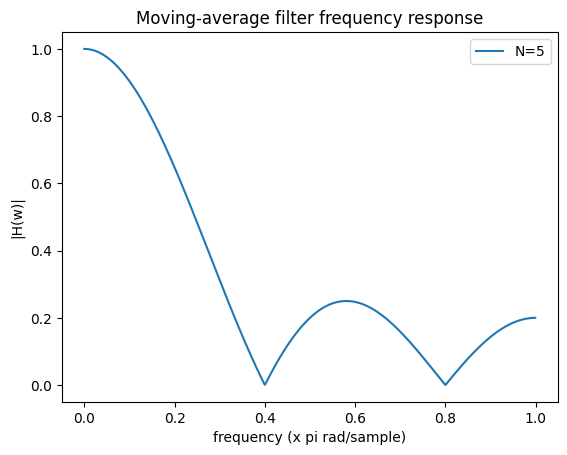

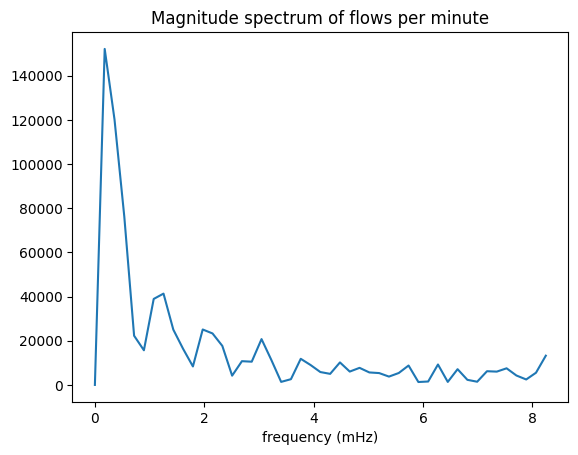

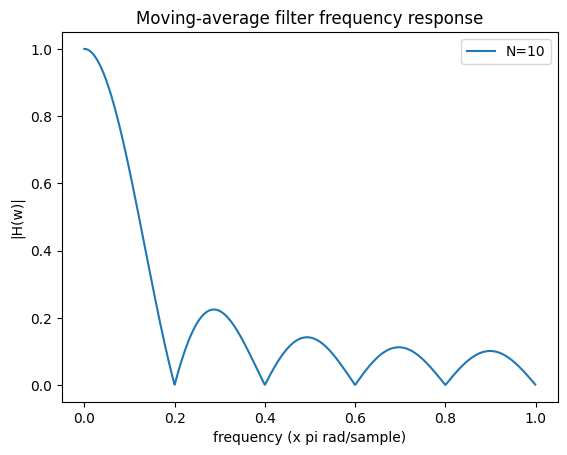

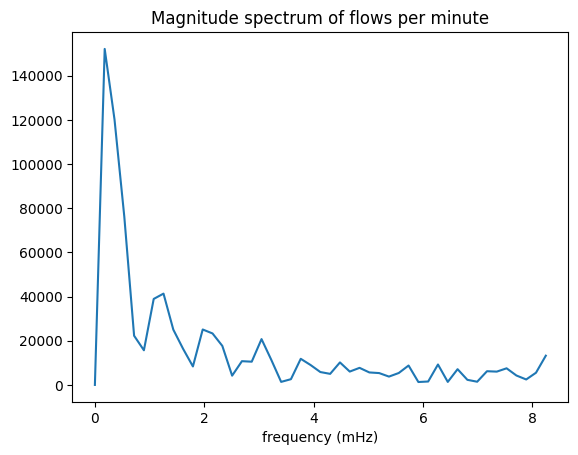

In [7]:
from scipy.signal import freqz 
for N in [3, 5, 10]: 
    w, h = freqz(np.ones(N) / N, worN=1024) 
    plt.plot(w / np.pi, abs(h), label=f'N={N}') 
    plt.xlabel('frequency (x pi rad/sample)'); 
    plt.ylabel('|H(w)|'); plt.legend() 
    plt.title('Moving-average filter frequency response'); 
    plt.show() 
    x = flows_per_min.values - flows_per_min.values.mean() 
    f = np.fft.rfftfreq(len(x), d=60) 
    plt.figure(); 
    plt.plot(f * 1000, abs(np.fft.rfft(x))) 
    plt.xlabel('frequency (mHz)'); 
    plt.title('Magnitude spectrum of flows per minute'); 
    plt.show()

In [8]:
from sklearn.ensemble import IsolationForest 
X = np.column_stack([flows_per_min.values, dur_per_min.values]) 
score = -IsolationForest(random_state=0).fit(X).score_samples(X) 
print('IsolationForest AUC', round(roc_auc_score(y, score), 3))

IsolationForest AUC 0.954


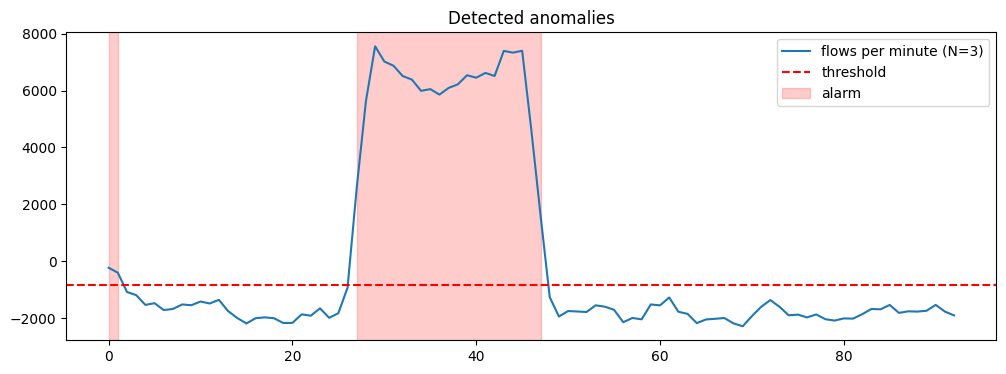

In [9]:
N = 3
s = causal_ma(x, N)
thr = s[N-1:start].mean() + 3 * s[N-1:start].std()
pred = s > thr
plt.figure(figsize=(12, 4))
ax = plt.gca()
plt.plot(s, label=f'flows per minute (N={N})')
plt.axhline(thr, color='red', linestyle='--', label='threshold')
plt.fill_between(range(len(y)), 0, 1, where=pred, transform=ax.get_xaxis_transform(), color='red', alpha=0.2, label='alarm')
plt.legend(); plt.title('Detected anomalies'); plt.show()